In [2]:
from Bio import SeqIO

for seq_record in SeqIO.parse("../data/SRR4163265.fasta", "fasta"):
# for seq_record in SeqIO.parse("../data/oligos.fasta", "fasta"):
    print(seq_record.id)
    print(repr(seq_record))
    print(len(seq_record))
    break

SRR4163265.1
SeqRecord(seq=Seq('GGAGGTACCATAATGGTCGGTAATCCTAACTCTGAAAGTGATAAACACCTTGTT...GAT'), id='SRR4163265.1', name='SRR4163265.1', description='SRR4163265.1 1 length=126', dbxrefs=[])
126


In [1]:
# Load model directly
from transformers import AutoTokenizer, AutoModelForPreTraining

tokenizer = AutoTokenizer.from_pretrained("lhallee/CodonBERT")
model = AutoModelForPreTraining.from_pretrained("lhallee/CodonBERT")

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


To use data.metrics please install scikit-learn. See https://scikit-learn.org/stable/index.html


ImportError: cannot import name 'AutoModelForPreTraining' from 'transformers' (/Users/ailinzhang/Desktop/sequence_optimization_with_CodonBERT/Sequence-Optimization-with-CodonBERT/.pixi/envs/default/lib/python3.13/site-packages/transformers/__init__.py)

In [ ]:
from transformers import AutoTokenizer, AutoModelForPreTraining, AutoModel
import torch
from Bio import SeqIO

# Load CodonBERT
tokenizer = AutoTokenizer.from_pretrained("lhallee/CodonBERT")
model = AutoModelForPreTraining.from_pretrained("lhallee/CodonBERT")

# Get one sequence from fasta
for seq_record in SeqIO.parse("../data/SRR4163265.fasta", "fasta"):
    dna_seq = str(seq_record.seq)
    break

print("Example sequence:", dna_seq[:60], "...")

# Tokenize 
inputs = tokenizer(
    dna_seq,
    return_tensors="pt",
    max_length=512,   # CodonBERT has a context window, truncate if longer
    truncation=True,
    padding="max_length"
)

# Run inference
with torch.no_grad():
    outputs = model(**inputs)

# Masked LM predictions
mlm_logits = outputs.prediction_logits   # [batch_size, seq_len, vocab_size]
print("MLM logits shape:", mlm_logits.shape)

base_model = AutoModel.from_pretrained("lhallee/CodonBERT")

with torch.no_grad():
    emb_outputs = base_model(**inputs)

embeddings = emb_outputs.last_hidden_state  # [batch_size, seq_len, hidden_dim]
print("Embeddings shape:", embeddings.shape)



Example sequence: GGAGGTACCATAATGGTCGGTAATCCTAACTCTGAAAGTGATAAACACCTTGTTACACCG ...
MLM logits shape: torch.Size([1, 512, 69])
Embeddings shape: torch.Size([1, 512, 768])


In [6]:
embeddings

tensor([[[ 0.2680, -0.1236,  0.0787,  ..., -0.1736, -0.9255,  0.1316],
         [ 0.2702, -0.2250,  0.3532,  ...,  0.1391, -1.0764,  0.5688],
         [ 0.5499, -0.4428,  0.3693,  ...,  0.2403, -0.6261,  0.5298],
         ...,
         [ 0.8073, -0.5289,  0.4486,  ...,  0.1888, -0.7543,  0.6473],
         [ 0.9092, -0.5641,  0.2510,  ...,  0.2096, -0.6932,  0.6053],
         [ 0.8399, -0.6432,  0.3131,  ...,  0.3048, -0.6281,  0.6040]]])

test the parquet of SRR

In [6]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent

sys.path.append(str(ROOT / "src"))

from pathlib import Path
from boto3.session import Session
from config import PROFILE_NAME, REGION_NAME

BUCKET = "sequence-data-ztgg"
KEY = "codonbert_inference/embeddings_batch_00001.parquet"
LOCAL_FILE = "embeddings_batch_00001.parquet"

session = Session(profile_name=PROFILE_NAME, region_name=REGION_NAME)
s3 = session.client("s3")

s3.download_file(BUCKET, KEY, LOCAL_FILE)

print("Downloaded:", LOCAL_FILE)

Downloaded: embeddings_batch_00001.parquet


In [7]:
import pandas as pd

df = pd.read_parquet("embeddings_batch_00001.parquet")

print(df.shape)
df.head()

(1000, 771)


,id,clean_seq,num_codons,emb_0,emb_1,emb_2,emb_3,emb_4,emb_5,emb_6,...,emb_758,emb_759,emb_760,emb_761,emb_762,emb_763,emb_764,emb_765,emb_766,emb_767
0,SRR4163265.1,GGA GGT ACC ATA ATG GTC GGT AAT CCT AAC TCT GA...,42,0.147193,-0.319087,0.243105,-0.270262,0.333919,-0.052783,-0.186103,...,0.021732,0.402986,0.139591,-0.451386,0.048015,-0.146438,0.134187,0.046472,-0.423647,0.629220
1,SRR4163265.1,TCC ACC GGA TCC ACC AGC ACT CGC GAA ACC ACG GA...,42,0.209312,-0.365283,0.215105,-0.119629,0.160537,0.252223,-0.188706,...,0.136594,0.234742,0.269765,-0.588419,0.135941,-0.212176,0.395797,-0.068766,-0.911109,0.378644
2,SRR4163265.2,GGA GGT ACC ATA ATG AGC GTC GGT GTT TGT ATT CC...,42,0.330041,-0.414726,0.446995,0.013615,0.276375,-0.067108,-0.254622,...,0.211351,0.268935,0.354959,-0.483760,0.128693,-0.262377,0.498039,0.063157,-0.551255,0.475222
3,SRR4163265.2,TCC ACC GGA TCC ACC AGT ACC AAC AAT GAT CTG CG...,42,0.114113,-0.227711,0.269597,-0.113284,0.283615,-0.054260,-0.170040,...,0.126437,0.234657,0.388725,-0.386815,0.108719,-0.063981,0.554737,-0.028477,-0.563726,0.352701
4,SRR4163265.3,GGA GGT ACC ATA ATG CAT TCT TTG CAA TTT GGG AC...,42,0.062851,-0.374458,-0.000700,-0.070906,0.336883,0.246255,-0.094347,...,0.068530,0.061557,0.463392,-0.198866,0.129833,-0.570290,0.334498,0.084416,-0.944296,0.244673


In [8]:
emb_cols = [c for c in df.columns if c.startswith("emb_")]

print("embedding columns:", len(emb_cols))
print("NaN count:", df[emb_cols].isna().sum().sum())
print(df[emb_cols].iloc[:, :5].describe())

embedding columns: 768
NaN count: 0
             emb_0        emb_1        emb_2        emb_3        emb_4
count  1000.000000  1000.000000  1000.000000  1000.000000  1000.000000
mean      0.159368    -0.343561     0.244004    -0.129252     0.334230
std       0.111712     0.128839     0.141415     0.118874     0.104064
min      -0.298914    -0.705794    -0.198356    -0.559666     0.051288
25%       0.092948    -0.430038     0.155242    -0.207994     0.263064
50%       0.165802    -0.332923     0.250238    -0.130813     0.333878
75%       0.229772    -0.250355     0.341197    -0.049173     0.406482
max       0.542085     0.025855     0.627776     0.348768     0.667457


Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


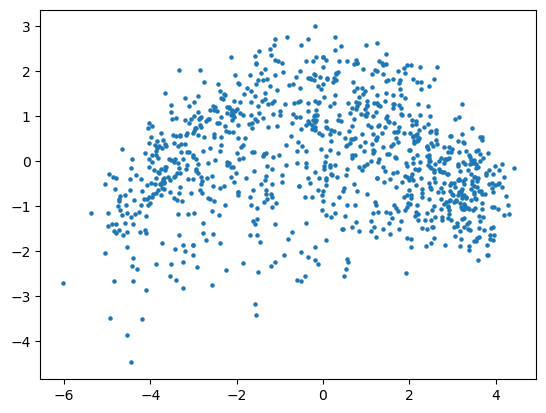

[0.38094935 0.08207572]
0.4630250715921152


In [13]:
import pandas as pd
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

df = pd.read_parquet("embeddings_batch_00001.parquet")

emb_cols = [c for c in df.columns if c.startswith("emb_")]

X = df[emb_cols].values

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.scatter(X_pca[:,0], X_pca[:,1], s=5)
plt.show()
print(pca.explained_variance_ratio_)
print(sum(pca.explained_variance_ratio_))

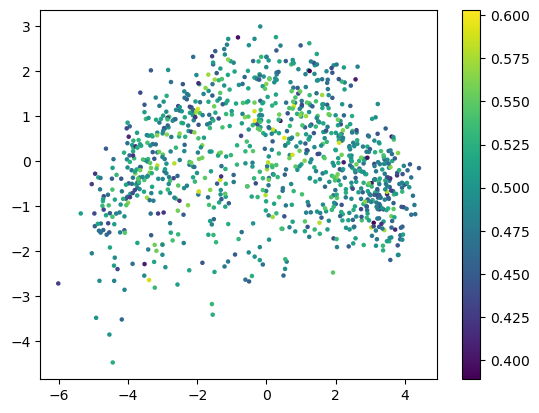

In [15]:
def gc_content(seq):
    seq = seq.replace(" ", "")
    return (seq.count("G") + seq.count("C")) / len(seq)

df["gc"] = df["clean_seq"].apply(gc_content)
plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=df["gc"],
    s=5
)
plt.colorbar()
plt.show()

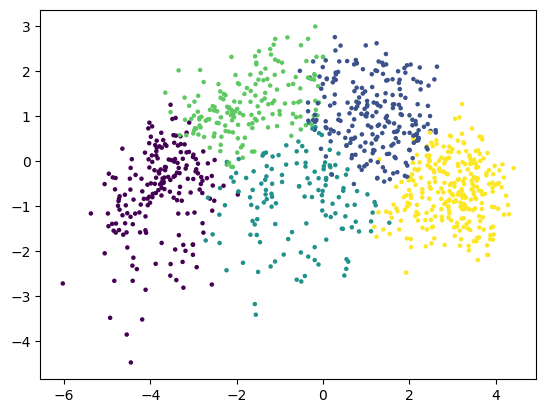

In [16]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=5)
labels = kmeans.fit_predict(X)

plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=labels,
    s=5
)

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


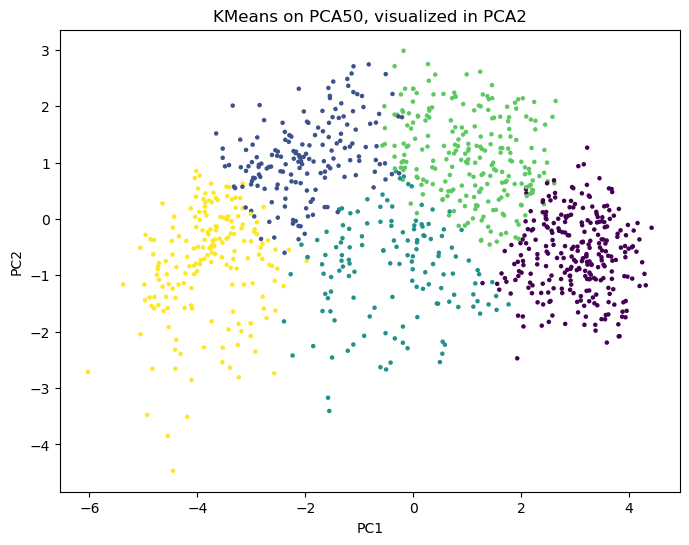

In [19]:
# 原始768维embedding

X = df[emb_cols].values

# PCA到50维

pca50 = PCA(n_components=50)

X50 = pca50.fit_transform(X)

print(

    "Variance explained by 50 PCs:",

    pca50.explained_variance_ratio_.sum()

)

# 在50维上聚类

kmeans = KMeans(

    n_clusters=5,

    random_state=0,

    n_init=10

)

labels = kmeans.fit_predict(X50)

# 用2维PCA做可视化

pca2 = PCA(n_components=2)

X2 = pca2.fit_transform(X)

plt.figure(figsize=(8,6))

plt.scatter(

    X2[:,0],

    X2[:,1],

    c=labels,

    s=5

)

plt.xlabel("PC1")

plt.ylabel("PC2")

plt.title("KMeans on PCA50, visualized in PCA2")

plt.show()

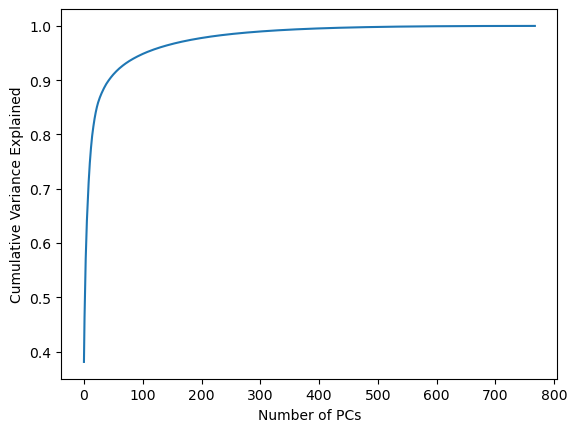

In [18]:
import numpy as np
pca = PCA()
pca.fit(X)

plt.plot(
    np.cumsum(pca.explained_variance_ratio_)
)
plt.xlabel("Number of PCs")
plt.ylabel("Cumulative Variance Explained")
plt.show()

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


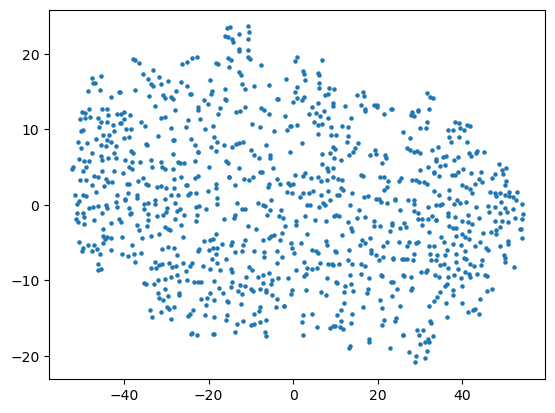

In [21]:
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# 先降到50维
X50 = PCA(n_components=50).fit_transform(X)

# 再TSNE到2维
X_tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=0
).fit_transform(X50)

plt.scatter(
    X_tsne[:,0],
    X_tsne[:,1],
    s=5
)
plt.show()

In [22]:
import io
import pandas as pd
from boto3.session import Session
from config import PROFILE_NAME, REGION_NAME

BUCKET = "sequence-data-ztgg"
PREFIX = "codonbert_inference/"

session = Session(profile_name=PROFILE_NAME, region_name=REGION_NAME)
s3 = session.client("s3")

dfs = []

for batch_num in range(1, 51):   # 先读前50个parquet
    key = f"{PREFIX}embeddings_batch_{batch_num:05d}.parquet"
    
    obj = s3.get_object(Bucket=BUCKET, Key=key)
    df = pd.read_parquet(io.BytesIO(obj["Body"].read()))
    
    df_sample = df.sample(n=min(200, len(df)), random_state=batch_num)
    df_sample["batch_num"] = batch_num
    
    dfs.append(df_sample)

df_big = pd.concat(dfs, ignore_index=True)

print(df_big.shape)
df_big.head()

(10000, 772)


,id,clean_seq,num_codons,emb_0,emb_1,emb_2,emb_3,emb_4,emb_5,emb_6,...,emb_759,emb_760,emb_761,emb_762,emb_763,emb_764,emb_765,emb_766,emb_767,batch_num
0,SRR4163265.255,GGA GGT ACC ATA ATG AAG TGC TAT TCT AAT GCT GC...,42,0.340668,-0.255581,0.347284,-0.293753,0.312910,0.054613,-0.404776,...,0.341613,0.243111,-0.458571,-0.061810,-0.365621,0.464160,0.086296,-0.722380,0.473898,1
1,SRR4163265.410,TCC ACC GGA TCC ACC TCG TGG AGA TCC GGA AGC TG...,42,0.136947,-0.470863,0.111463,-0.027042,0.378558,0.167853,-0.050181,...,0.192857,0.327275,-0.424617,0.238945,-0.385818,0.420971,-0.051098,-1.020140,0.532079,1
2,SRR4163265.227,TCC ACC GGA TCC ACC AAC GTA CTG TCG AAC ACC GA...,42,0.072800,-0.555598,-0.036799,-0.014774,0.367968,-0.076444,0.069683,...,0.100991,0.511342,-0.450871,0.199285,-0.181128,0.406825,-0.105366,-0.913951,0.307183,1
3,SRR4163265.185,GGA GGT ACC ATA AGA ACC TAC ATC GAT TAC CTC AT...,42,0.271704,-0.399070,0.165164,-0.191166,0.345504,0.187433,0.212529,...,0.195807,0.405877,-0.521896,0.095679,-0.224284,0.308807,-0.086681,-0.907441,0.279918,1
4,SRR4163265.122,GGA GGT ACC ATA ATG GTT GGT CAA TTG CAT ATG GG...,42,0.100763,-0.304149,0.190129,-0.208552,0.121983,-0.286979,-0.253633,...,0.414139,0.115637,-0.291165,0.114418,0.032086,-0.076174,0.193120,-0.545009,0.667286,1


Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


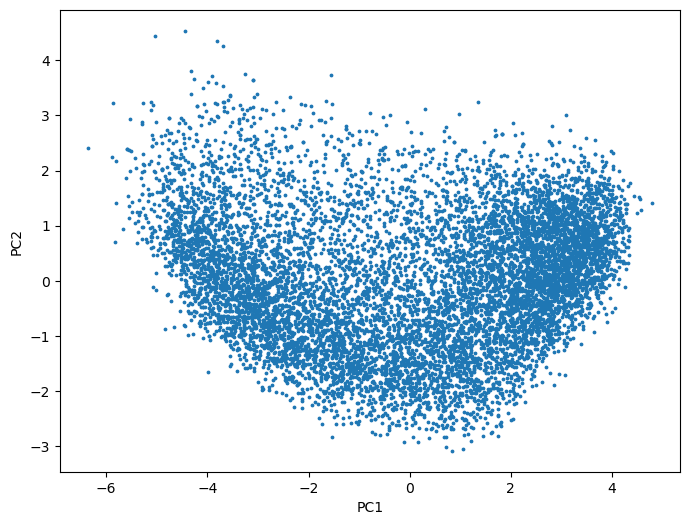

In [23]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

emb_cols = [c for c in df_big.columns if c.startswith("emb_")]
X = df_big[emb_cols].values

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

print(pca.explained_variance_ratio_)
print(pca.explained_variance_ratio_.sum())

plt.figure(figsize=(8,6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], s=3)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

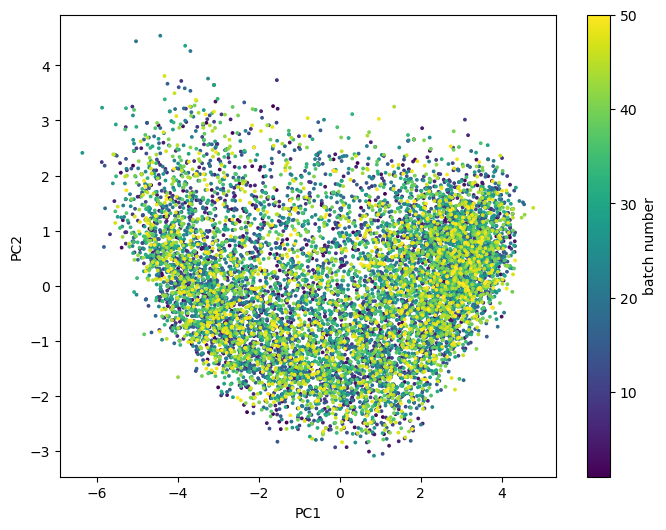

In [24]:
plt.figure(figsize=(8,6))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df_big["batch_num"],
    s=3
)
plt.colorbar(label="batch number")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

In [26]:
df_big["pc1"] = X_pca[:,0]

left = df_big.nsmallest(20, "pc1")
right = df_big.nlargest(20, "pc1")

In [29]:
left[["id","clean_seq","pc1"]]


,id,clean_seq,pc1
5327,SRR4163265.13129,TCC ACC GGA TCC ACC TAA GGT GGT TCC TTC TCC AA...,-6.361055
1620,SRR4163265.4261,TCC ACC GGA TCC ACC ACG TAC ATA AGG CTT GGA GT...,-5.880503
5789,SRR4163265.14412,TCC ACC GGA TCC ACC ACG AAT CTA AGG CTA GGA GT...,-5.872810
3141,SRR4163265.7632,TCC ACC GGA TCC ACC AGA GGT AGA ACA TGG ACA AG...,-5.827161
2644,SRR4163265.6561,TCC ACC GGA TCC ACC AGA GCT AGA GCA GCA ATC TT...,-5.809181
3552,SRR4163265.8801,TCC ACC GGA TCC ACC AGA AGC GTG AGT GTA AGA TA...,-5.798701
1483,SRR4163265.3929,TCC ACC GGA TCC ACC AGA ACG AGA GCA ACA ATC TT...,-5.677428
5321,SRR4163265.13082,TCC ACC GGA TCC ACC TGG AGA ACA ATT ATC AGG TT...,-5.607174
8030,SRR4163265.20190,TCC ACC GGA TCC ACC TAC ATG TTG TGC ATT ACG AG...,-5.594400
9149,SRR4163265.22977,TCC ACC GGA TCC ACC ATA ATC CCA TCC CAT ACA CG...,-5.584233


In [28]:
right[["id","clean_seq","pc1"]]

,id,clean_seq,pc1
9071,SRR4163265.22533,GGA GGT CCC ATA ATG ATT GGT CGT TGC ACT TTA TA...,4.781852
8208,SRR4163265.20959,GGA GGT ACC ATA ATG ATC GAA ATG CAA GTT CCC GC...,4.568551
3562,SRR4163265.8771,GGA GGT CCC ATA ATG CTT TAT TGT TGT GGA GGT AA...,4.556648
3370,SRR4163265.8290,GGA GGT CCC ATA ATG ATC GAA ATG TGT GTT CCC GC...,4.527948
8531,SRR4163265.21464,GGA GGT ACC ATA ATG CTA TAT TGC TGT GGT GGT AA...,4.495272
4359,SRR4163265.10713,GGA GGT ACC ATA ATG ATG TAT GCT GTA CGT TCC GT...,4.439305
5677,SRR4163265.14162,GGA GGT ACC ATA ATG GAT GGT TGT CAT CTT GTT AG...,4.352673
9859,SRR4163265.25010,GGA GGT ACC ATA ATG CGT CGC GTT GAA ATT CTT TC...,4.333856
2454,SRR4163265.6062,GGA GGT ACC ATA ATG AAA GTT GGT ACT AGT TGG CG...,4.333095
3469,SRR4163265.8561,GGA GGT CCC ATA ATG AAG TGT TAT TCT AAC GCG GC...,4.332872
